# Unit 7 – A single perceptron
A perceptron computes z = w·x + b and outputs 1 if z > 0, else 0. Learning rule: after each example, w ← w + η (target − output) x and b ← b + η (target − output).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.random.seed(42)

Epochs needed: 3 | errors per epoch: [25, 3, 0]
weights: [0.248 0.139] bias: -1.2 | accuracy: 1.0


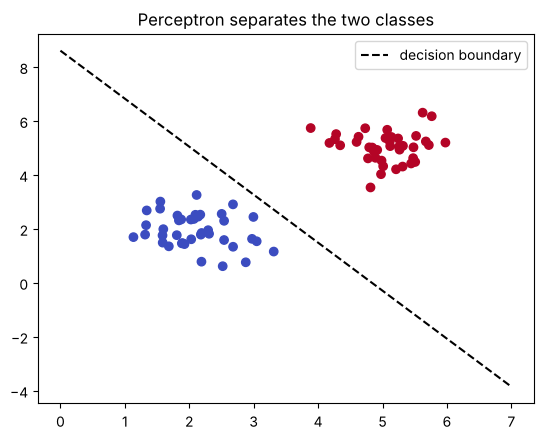

In [2]:
class Perceptron:
    def __init__(self, n_inputs, lr=0.1, seed=0):
        rng = np.random.RandomState(seed)
        self.w = rng.normal(0, .1, n_inputs); self.b = 0.0; self.lr = lr; self.rng = rng
    def predict(self, X):
        return (X @ self.w + self.b > 0).astype(int)
    def fit(self, X, y, epochs=50):
        errors_per_epoch = []
        for _ in range(epochs):
            errors = 0
            for j in self.rng.permutation(len(X)):          # shuffle each epoch
                xi, ti = X[j], y[j]
                out = int(xi @ self.w + self.b > 0)
                update = self.lr * (ti - out)
                self.w += update * xi; self.b += update
                errors += int(update != 0)
            errors_per_epoch.append(errors)
            if errors == 0: break
        return errors_per_epoch

# two linearly separable blobs
rng = np.random.RandomState(1)
X = np.vstack([rng.normal([2, 2], .6, (40, 2)), rng.normal([5, 5], .6, (40, 2))])
y = np.array([0] * 40 + [1] * 40)

p = Perceptron(2, lr=0.1); errs = p.fit(X, y, epochs=50)
print('Epochs needed:', len(errs), '| errors per epoch:', errs)
print('weights:', p.w.round(3), 'bias:', round(p.b, 3), '| accuracy:', (p.predict(X) == y).mean())

xx = np.linspace(0, 7, 50)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm')
plt.plot(xx, -(p.w[0] * xx + p.b) / p.w[1], 'k--', label='decision boundary')
plt.legend(); plt.title('Perceptron separates the two classes'); plt.show()

## Experiment – learning rate, and separability

In [3]:
rows = []
for lr in (0.001, 0.01, 0.1, 1.0):
    q = Perceptron(2, lr=lr, seed=0); e = q.fit(X, y, 200)
    rows.append({'learning_rate': lr, 'epochs_to_converge': len(e), 'final_accuracy': (q.predict(X) == y).mean()})
display(pd.DataFrame(rows))

# overlapping classes: the perceptron can never reach zero errors
X2 = np.vstack([rng.normal([3, 3], 1.2, (60, 2)), rng.normal([4, 4], 1.2, (60, 2))]); y2 = np.array([0] * 60 + [1] * 60)
q = Perceptron(2, lr=0.1); e = q.fit(X2, y2, 100)
print('\nOverlapping data: epochs run =', len(e), '| fewest errors in any epoch =', min(e), '| last-epoch errors =', e[-1], '| final accuracy =', round((q.predict(X2) == y2).mean(), 3))

,learning_rate,epochs_to_converge,final_accuracy
0,0.001,10,1.0
1,0.010,3,1.0
2,0.100,3,1.0
3,1.000,3,1.0



Overlapping data: epochs run = 100 | fewest errors in any epoch = 37 | last-epoch errors = 39 | final accuracy = 0.725


## Observations
* On separable data the perceptron converged in 3 epochs at learning rates 0.01, 0.1 and 1.0; only the very small rate (0.001) was slower, at 10 epochs.
* On overlapping classes no weight vector can separate the data. The perceptron never reached zero errors in 100 epochs (best epoch: 37 mistakes) and ended at 72.5 % accuracy: **the perceptron rule only converges for linearly separable data**.